# <center>Annotation d'images<br /> Workshop</center>

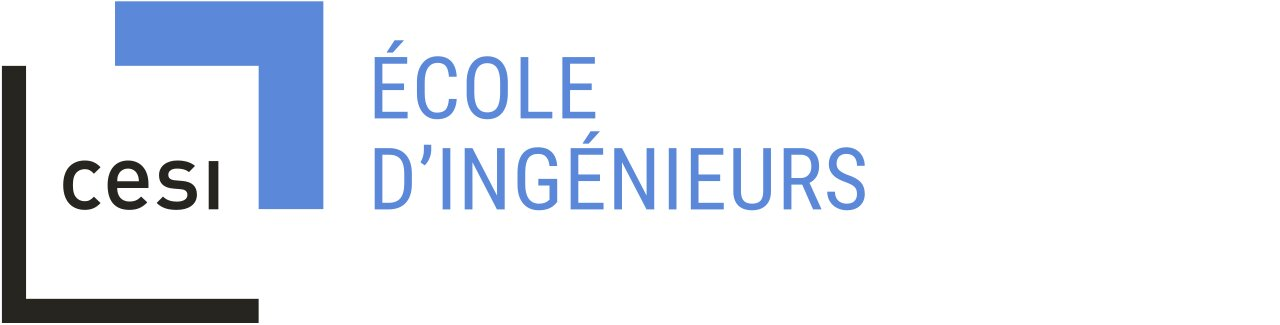
Concepteur : Nassim HADDAM
</div>

L'objectif de de ce workshop est de vous faire acquérir les notions nécessaires pour effectuer le workshop d'[annotation d'images](https://fr.wikipedia.org/wiki/Annotation_automatique_d%27images) (ou sous-titrage d'images). Dans ce workshop, vous allez devoir utiliser les CNNs (pour création d’attributs utiles à l’annotation) ainsi que les RNNs (pour faire l’annotation à proprement parler). Vous allez aussi devoir faire **beaucoup** de prétraitements. Ce workshop portera essentiellement sur cette partie et donnera des indications sur l'architecture du réseau qui servira à faire de l'annotation. On commencera d'abord par importer les bibliothèques qui nous intéressent.

Vous devez, donc, ré-exécuter les cellules correspondant à la préparation des données du workshop précédent en allant du chargement des données jusqu'au prétraitements des images et des annotations.
<br><br>
<b>Imports</b>

In [1]:
# Imports principaux
import tensorflow as tf
import matplotlib.pyplot as plt
import collections
import random
import re
import numpy as np
import os
import time
import json
import math
from pathlib import Path
from glob import glob
from PIL import Image
import pickle
from tqdm import tqdm

# Option désactivée par défaut : activer uniquement sur un matériel compatible.
USE_MIXED_PRECISION = False
if USE_MIXED_PRECISION:
    tf.keras.mixed_precision.set_global_policy("mixed_float16")


<b>Chargement des données</b>

In [70]:
# Sélection déterministe par image : toutes les captions d'une image restent ensemble.
MAX_IMAGES = {"train": 30000, "validation": 10000}
SUBSET_SEED = 42
DATA_DIR = Path("data")
ANNOTATION_FILES = {
    "train": DATA_DIR / "annotations" / "captions_train2014.json",
    "validation": DATA_DIR / "annotations" / "captions_val2014.json",
}
IMAGE_DIRS = {
    "train": DATA_DIR / "train2014",
    "validation": DATA_DIR / "val2014",
}

def select_image_ids(annotation_data, split):
    """Sélectionne au plus MAX_IMAGES identifiants uniques avec une seed fixe."""
    image_ids = sorted({a["image_id"] for a in annotation_data["annotations"]})
    rng = random.Random(SUBSET_SEED)
    return set(rng.sample(image_ids, min(MAX_IMAGES[split], len(image_ids))))

def load_split(split):
    with ANNOTATION_FILES[split].open("r", encoding="utf-8") as f:
        annotation_data = json.load(f)
    selected_ids = select_image_ids(annotation_data, split)
    prefix = "train" if split == "train" else "val"
    image_to_captions = collections.defaultdict(list)
    for annotation in annotation_data["annotations"]:
        if annotation["image_id"] in selected_ids:
            filename = f"COCO_{prefix}2014_{annotation['image_id']:012d}.jpg"
            image_path = IMAGE_DIRS[split] / filename
            image_to_captions[image_path].append(
                f"<start> {annotation['caption']} <end>"
            )
    image_paths = sorted(image_to_captions)
    captions, image_names = [], []
    for image_path in image_paths:
        captions.extend(image_to_captions[image_path])
        image_names.extend([str(image_path)] * len(image_to_captions[image_path]))
    print(f"{split}: {len(image_paths)} images uniques, {len(captions)} captions")
    return image_names, captions

img_name_train, train_captions = load_split("train")
img_name_val, val_captions = load_split("validation")
# Alias conservé pour la compatibilité avec les cellules pédagogiques existantes.
validation_captions = val_captions


train: 30000 images uniques, 150075 captions
validation: 10000 images uniques, 50041 captions


In [73]:
# Extraction reprenable : un fichier par image, stockage float16.
FEATURES_DIR = Path("features/inception_grid_fp16")
EXTRACTION_BATCH_SIZE = 64
FEATURE_SHAPE = (64, 2048)
FEATURE_PATHS = {}
for split, image_names in (("train", img_name_train), ("validation", img_name_val)):
    for name in sorted(set(image_names)):
        image_id = int(Path(name).stem.rsplit("_", 1)[-1])
        FEATURE_PATHS[name] = FEATURES_DIR / split / f"{image_id}.npy"

image_model = tf.keras.applications.InceptionV3(include_top=False, weights="imagenet")
image_model.trainable = False
image_features_extract_model = tf.keras.Model(image_model.input, image_model.layers[-1].output)

def load_image(image_path):
    img = tf.io.read_file(image_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (299, 299))
    img = tf.keras.applications.inception_v3.preprocess_input(img)
    return img, image_path

def valid_feature_file(path):
    if not path.is_file():
        return False
    try:
        values = np.load(path, allow_pickle=False)
        return (values.shape == FEATURE_SHAPE
                and values.dtype in (np.dtype("float16"), np.dtype("float32"))
                and bool(np.isfinite(values).all()))
    except (OSError, ValueError, EOFError):
        return False

def save_feature_file(path, values):
    values = np.asarray(values, dtype=np.float16)
    if values.shape != FEATURE_SHAPE or not np.isfinite(values).all():
        raise ValueError(f"Features invalides : {path}")
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(".tmp.npy")
    np.save(temporary, values, allow_pickle=False)
    temporary.replace(path)

def extract_features(image_paths, dataset_name):
    pending = []
    reused = migrated = 0
    for name in tqdm(sorted(set(image_paths)), desc=f"Vérification {dataset_name}"):
        destination = FEATURE_PATHS[name]
        if valid_feature_file(destination):
            reused += 1
            continue
        legacy = Path(name + ".npy")
        if valid_feature_file(legacy):
            save_feature_file(destination, np.load(legacy, allow_pickle=False))
            migrated += 1
        else:
            pending.append(name)
    print(f"{dataset_name} : {reused} présentes, {migrated} reprises depuis les anciens .npy, {len(pending)} à extraire.")
    if not pending:
        return
    image_dataset = tf.data.Dataset.from_tensor_slices(pending)
    image_dataset = image_dataset.map(
        load_image, num_parallel_calls=tf.data.AUTOTUNE
    ).batch(EXTRACTION_BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    total = math.ceil(len(pending) / EXTRACTION_BATCH_SIZE)
    for images, paths in tqdm(image_dataset, total=total, desc=f"Extraction {dataset_name}"):
        features = image_features_extract_model(images, training=False)
        features = tf.reshape(features, (tf.shape(features)[0], 64, 2048))
        for values, name in zip(features.numpy(), paths.numpy()):
            save_feature_file(FEATURE_PATHS[name.decode("utf-8")], values)

extract_features(img_name_train, "train")
extract_features(img_name_val, "validation")


Vérification train:  17%|█▋        | 5040/30000 [00:06<00:30, 811.85it/s]


KeyboardInterrupt: 

**Pré-traitement des annotations**

In [74]:
# Tokenizer appris exclusivement sur les captions du train.
def calc_max_length(tensor):
    return max(len(t) for t in tensor)

top_k = 5000
tokenizer = tf.keras.preprocessing.text.Tokenizer(
    num_words=top_k, oov_token="<unk>",
    filters='!"#$%&()*+.,-/:;=?@[\]^_`{|}~ '
)
tokenizer.fit_on_texts(train_captions)
tokenizer.word_index["<pad>"] = 0
tokenizer.index_word[0] = "<pad>"

train_seqs = tokenizer.texts_to_sequences(train_captions)
max_length = calc_max_length(train_seqs)
cap_train = tf.keras.preprocessing.sequence.pad_sequences(train_seqs, padding="post")
val_seqs = tokenizer.texts_to_sequences(val_captions)
cap_val = tf.keras.preprocessing.sequence.pad_sequences(
    val_seqs, maxlen=max_length, padding="post"
)
print("Token <start> :", tokenizer.word_index.get("<start>"))
print("Token <end>   :", tokenizer.word_index.get("<end>"))


Token <start> : 3
Token <end>   : 4


# 1 Formation du jeu d'entrainement et de test :
Vous devez ensuite séparer le dataset en deux partie : un jeu d'entrainement et un jeu de test. Le code qui effectue ces opérations est détaillé dans la cellule suivante.

In [75]:
# Les splits sont déjà indépendants : train2014 et val2014.
# Chaque image est répétée pour chacune de ses captions, sans mélanger les images.
print(f"Train : {len(set(img_name_train))} images uniques, {len(cap_train)} captions")
print(f"Validation : {len(set(img_name_val))} images uniques, {len(cap_val)} captions")


Train : 30000 images uniques, 150075 captions
Validation : 10000 images uniques, 50041 captions


Création d’un jeu de données d’entrainement représenté par une instance [`tf.data.Dataset`](https://www.tensorflow.org/api_docs/python/tf/data/Dataset) partant du jeu de données de base (les noms des fichiers et des annotations du jeu d’entrainement). La classe `tf.data.Dataset` sert à représenter des jeu de données volumineux et facilitent les prétraitements de ceux-ci.

In [76]:
# Paramètres et pipeline tf.data rapide.
BATCH_SIZE = 128
BUFFER_SIZE = 1000
embedding_dim = 256
units = 512
vocab_size = top_k + 1
num_steps = max(1, math.ceil(len(img_name_train) / BATCH_SIZE))
num_validation_steps = max(1, math.ceil(len(img_name_val) / BATCH_SIZE))
features_shape = 2048
attention_features_shape = 64
USE_CACHE = True  # True pour activer un cache disque local.

def map_func(img_name, cap):
    img_tensor = np.load(FEATURE_PATHS[img_name.decode("utf-8")], allow_pickle=False)
    if img_tensor.shape != FEATURE_SHAPE:
        raise ValueError(f"Forme de features incorrecte : {img_tensor.shape}")
    return img_tensor.astype(np.float32), cap

def make_feature_dataset(image_names, captions, cache_path=None, shuffle_data=False):
    ds = tf.data.Dataset.from_tensor_slices((image_names, captions))
    ds = ds.map(
        lambda name, cap: tf.numpy_function(
            map_func, [name, cap], [tf.float32, tf.int32]
        ),
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    if cache_path is not None:
        ds = ds.cache(cache_path)
    if shuffle_data:
        ds = ds.shuffle(BUFFER_SIZE, seed=SUBSET_SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

dataset = make_feature_dataset(
    img_name_train, cap_train, "./tf_cache_features_fp16_v1_train" if USE_CACHE else None, True
)
validation_dataset = make_feature_dataset(
    img_name_val, cap_val, "./tf_cache_features_fp16_v1_validation" if USE_CACHE else None, False
)


# 2 Le modèle :
Par rapport au modèle, la dernière couche convolutive d'`InceptionV3` est de la forme `(8, 8, 2048)`. Ce vecteur a été remodelé en la forme `(64, 2048)` lors de du stockage au niveau du disque. Ce vecteur est ensuite passé à travers l'encodeur CNN (qui se compose d'une seule couche entièrement connectée). Le RNN s'occupera de prédire pour ce vecteur le mot suivant dans l'annotation. [L'image](https://github.com/Hvass-Labs/TensorFlow-Tutorials/blob/master/22_Image_Captioning.ipynb) ci-dessous reprend un exemple d'une architecture très basique d'un système d'annotation utilisant un CNN et un RNN.

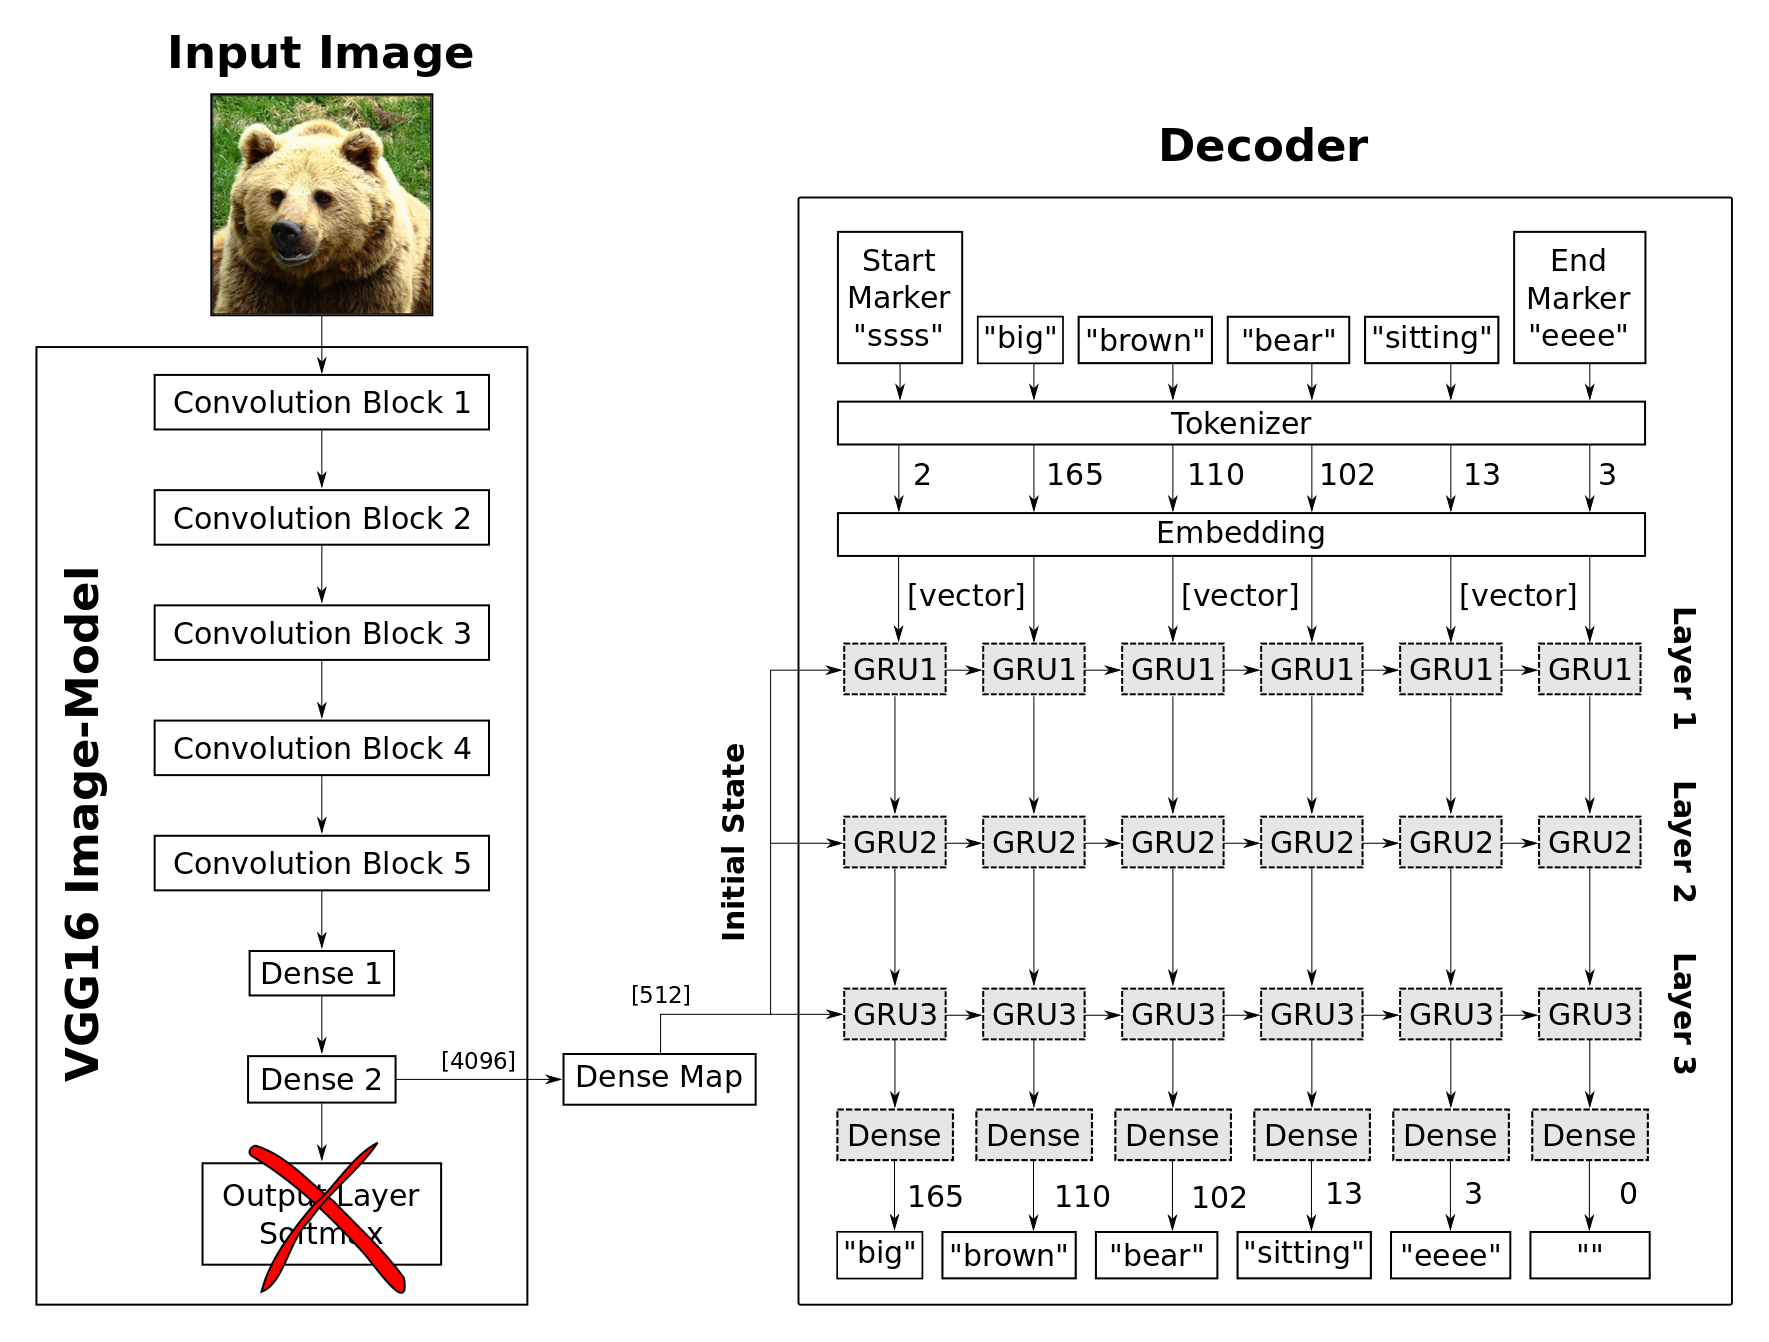

Dans cet exemple le captioning se fait de cette façon:
<ul>
    <li>L'image est passée à travers le CNN pour avoir une représentation compacte de celui-ci. Cette représentation est retournée par la couche `Dense 2` de taille 4096.</li>
    <li>Cette représentation est réduite en la passant à la couche dense `Dense Map` pour etre mise en entrée comme etat caché initial aux cellules du RNN.</li>
    <li>La partie RNN est composée de <a href="https://openclassrooms.com">GRU</a> (Gated Reccurent Unit). Cette partie est constituée de 3 couches. Une couche représentant de manière assez sommaire un niveau d'abstraction du langage. </li>
    <li>Le RNN a en entrée l'annotation ainsi que l'image en forme compacte, et retourne pour chaque colonne le mot suivant le mot en entrée au niveau de la colonne.</li>
    <li>Les annotations sont représentées en liste de mot. Cette liste est inexploitable par le RNN, elle est donc passée à un module qui remplace chaque mot par un entier (ou jeton entier), puis par un autre module qui projette chaque jeton en un vecteur dont les éléments sont entre -1 et 1.</li>
</ul>

Votre système d'annotation suivra de manière assez globale, le même principe que montrée dans l'image ci-dessous, néanmoins il contiendra des différences essentielles le distinguant de cet exemple. La système contiendra, notamment, un mécanisme d'attention (expliqué dans [article](https://arxiv.org/pdf/1502.03044.pdf) et dans [la video](https://www.youtube.com/watch?v=uCSTpOLMC48&list=WL&index=257)) dont la fonction est d'amener le réseau de neurones à donner une plus grande importance dans ses prédictions de l'annotation aux parties de l'images les plus parlantes et les plus pertinentes.

**L'encodeur CNN :**

L'encodeur CNN produit une représentation adéquate de l'image qu'il transmet au décodeur RNN pour la légender. Le CNN a en entrée les caractéristiques des images déjà prétraitées par InceptionV3 et stockées sur disque. 

Petite remarque, dans la partie CNN de ce réseau de neurones, la dernière couche convolutive n’est pas aplatie comme dans le cas du précédent workshop sur les CNNs. Rappelez-vous que les images issues du prétraitement par InceptionV3 étaient de la forme 8x8x2048. Ces images ont été remodelées pour avoir la taille 64x2048. Cela signifie que cette représentation contient pour chacune des 64 positions de l’image prétraitée les 2048 caractéristiques extraites par InveptoinV3. Et donc, l’entrée du décodeur CNN est un batch ou chaque élément est constitué des 2048 caractéristiques des 64 positions de l’image prétraitée (qui était à l’origine 8x8). La couche dense qui suit calcule une nouvelle représentation de l’image de taille 64x256 ou chaque position de l’image a donc 256 caractéristiques. Les poids sont les mêmes pour les neurones de mêmes position qui se trouvent sur la même colonne dans l’image prétraitée (qui sont associées à la même caractéristique de l’image). Ceci provient de la manière qu’a la [couche dense]( https://www.tensorflow.org/api_docs/python/tf/keras/layers/Dense) de gérer les opérations matricielles dans tensorflow.

L’avantage de cette représentation par rapport à la représentation aplatie est de préserver de l’information spatiale au niveau des couches du réseau de neurones. Ceci permettra au mécanisme d’attention de la partie RNN de détecter les positions intéressantes au niveau de l’image et de renseigner l’algorithme sur quelle zone il devra porter le plus d’importance pour légender l’image.

In [77]:
class CNN_Encoder(tf.keras.Model):
    # Comme les images sont déjà prétraités par InceptionV3 est représenté sous forme compacte
    # L'encodeur CNN ne fera que transmettre ces caractéristiques à une couche dense
    def __init__(self, embedding_dim):
        super(CNN_Encoder, self).__init__()
        # forme après fc == (batch_size, 64, embedding_dim)
        self.fc = tf.keras.layers.Dense(embedding_dim)

    def call(self, x):
        x = self.fc(x)
        x = tf.nn.relu(x)
        return x

**Le mécanisme d'attention :**

Le mécanisme d’attention ressemble beaucoup à une cellule [RNN classique]( https://fr.wikipedia.org/wiki/R%C3%A9seau_de_neurones_r%C3%A9currents), mais avec quelques différences. La partie de l’attention a en entrée la représentation de l’image prétraitée retournée par le CNN ainsi que la valeur courante de l’état cachée du GRU, et en sortie le **vecteur du contexte** qui reflète les caractéristiques les plus importantes de l’image. Une étape intermédiaire pour calculer ce vecteur consiste à calculer les **poids d’attention** qui représentent l’importance de chaque position de l’image (il y en a 64) dans la prédiction de son annotation.

La représentation de l’image donnée en entrée est transformée au début de la même manière que pour le CNN en la passant à une couche dense de taille `units`. De même, l’état caché est aussi passé à une couche dense de taille `units`. La nouvelle représentation de l’image est ensuite additionnée à l’état caché puis passée à une fonction d’activation de type [`tanh`](https://fr.wikipedia.org/wiki/Tangente_hyperbolique) comme pour les cellules classiques de RNN. À ce niveau-là, on aura une représentation des données de taille `64xunits` contenant un mélange d’informations sur l’image et sur le texte de l’annotation. Un score est ensuite associé à chacune des positions en passant cette représentation à une couche dense. Ces scores sont normalisés avec une couche softmax pour produire le vecteur des **poids d’attention**. 

Finalement, chaque caractéristique de la représentation de l’image en entrée sera multipliée (pondérée) par le vecteur d’attention. Après quoi, on prend la somme de chaque caractéristique le long des positions (les lignes de la représentation) pour former le **vecteur du contexte**.

De façon globale, on peut dire que le vecteur d’attention dépend de scores qui sont appris à partir d’une représentation spatiale et textuelle de l’image. Ce vecteur d’attention renvoie la pertinence de chaque position et sert à calculer le vecteur du contexte qui nous donnera l’importance des caractéristiques de l’image.

In [88]:
class BahdanauAttention(tf.keras.Model):
    def __init__(self, units):
        super(BahdanauAttention, self).__init__()
        self.W1 = tf.keras.layers.Dense(units)
        self.W2 = tf.keras.layers.Dense(units)
        self.V = tf.keras.layers.Dense(1)

    def call(self, features, hidden):
        # Ajoute un axe temporel à l'état caché
        hidden_with_time_axis = tf.expand_dims(hidden, 1)

        attention_hidden_layer = tf.nn.tanh(
            self.W1(features) + self.W2(hidden_with_time_axis)
        )

        # Score non normalisé pour chaque caractéristique de l'image
        score = self.V(attention_hidden_layer)

        attention_weights = tf.nn.softmax(score, axis=1)

        # Somme pondérée des caractéristiques de l'image
        context_vector = attention_weights * features
        context_vector = tf.reduce_sum(context_vector, axis=1)

        return context_vector, attention_weights

**Le décodeur RNN :**

Le rôle du décodeur RNN est d’utiliser la représentation prétraitée de l’image de prédire sa légende mot par mot. Ce RNN à une seule cellule de type [GRU]( https://en.wikipedia.org/wiki/Gated_recurrent_unit). Le GRU a un état caché qui représente la mémoire des derniers éléments vu par celui-ci. Le GRU met à jour son état avant de le retourner, pour cela il utilise certains mécanismes de mémorisation qui sont assez sophistiqués.

Le décodeur est structuré comme suit, à chaque appel du RNN, le mot courant ainsi que la représentation de l’image et l’état caché du GRU sont donnés en entrée du RNN. Comme les mots sont représentés par des entiers, on doit faire passer ceux-ci par une couche dite [embedding layer]( https://www.tensorflow.org/api_docs/python/tf/keras/layers/Embedding) qui se chargera de calculer une représentation vectorielle de taille `output_dim` partant du nombre représentant le mot. 

À côté de ça, le mécanisme d’attention fournit un vecteur représentant **le contexte** de l’image c-à-d un vecteur qui nous renseigne sur les caractéristiques dominantes de l’image. Ce vecteur est calculé par un appel du mécanisme d’attention en lui fournissant en entrée les caractéristiques de l’image encodées par le CNN ainsi que l’état caché du GRU qui résume l’historique des mots vues par le RNN jusqu’à présent. 

Ensuite, le mot courant et le contexte sont concaténée pour former le vecteur d’entrée du GRU qui à son tour calcule l’état à l’étape suivante. Cet état est passée par une couche dense de taille `units` puis la sortie de cette couche est passée à une autre couche dense de taille `vocab_size` qui retourne le score associé à chaque mot du vocabulaire afin de prédire le mot suivant.

In [89]:
class RNN_Decoder(tf.keras.Model):
    def __init__(self, embedding_dim, units, vocab_size):
        super(RNN_Decoder, self).__init__()
        self.units = units

        self.embedding = tf.keras.layers.Embedding(vocab_size, embedding_dim)
        self.gru = tf.keras.layers.GRU(
            self.units,
            return_sequences=True,
            return_state=True,
            recurrent_initializer='glorot_uniform',
            dropout=0.3,           # Dropout sur les entrées
            recurrent_dropout=0.3
        )
        self.fc1 = tf.keras.layers.Dense(self.units)
        self.fc2 = tf.keras.layers.Dense(vocab_size)
        self.attention = BahdanauAttention(self.units)

    def call(self, x, features, hidden):
        context_vector, attention_weights = self.attention(features, hidden)

        x = self.embedding(x)
        x = tf.concat([tf.expand_dims(context_vector, 1), x], axis=-1)

        output, state = self.gru(x)
        y = self.fc1(output)
        y = tf.nn.relu(y)

        # Utiliser la dimension de y, et non celle de x.
        y = tf.reshape(y, (-1, y.shape[2]))
        y = self.fc2(y)

        return y, state, attention_weights

    def reset_state(self, batch_size):
        return tf.zeros((batch_size, self.units))

**Combiner la partie encodeur et décodeur :**

Vous devez compléter la partie du code pour la création de l'encodeur et du décodeur.

In [81]:
# Création de l'encodeur
encoder = CNN_Encoder(embedding_dim)

# Création du décodeur
decoder = RNN_Decoder(embedding_dim, units, vocab_size)


In [82]:
# Optimiseur ADAM
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)

# La fonction de perte
loss_object = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=True, reduction='none')

def loss_function(real, pred):
    mask = tf.math.logical_not(tf.math.equal(real, 0))
    loss_ = loss_object(real, pred)

    mask = tf.cast(mask, dtype=loss_.dtype)
    loss_ *= mask

    return tf.reduce_mean(loss_)

Pour garder la trace de votre apprentissage et la sauvegarder, vous pouvez utiliser la classe [`tf.train.Checkpoint`](https://www.tensorflow.org/api_docs/python/tf/train/Checkpoint).

In [83]:
# Checkpoint du meilleur modèle (un seul fichier conservé).
ckpt = tf.train.Checkpoint(encoder=encoder, decoder=decoder, optimizer=optimizer)
best_ckpt_manager = tf.train.CheckpointManager(
    ckpt, "./checkpoints/best", max_to_keep=1
)


Initialisation de l'époque de début d’entrainement dans `start_epoch`. La classe `tf.train.Checkpoint` permet de poursuivre l’entrainement là ou vous l’avez laissé s’il avait été interrompu auparavant.

In [86]:
# L'entraînement démarre à zéro ; le meilleur checkpoint sera restauré à la fin.
start_epoch = 0
best_val_loss = float("inf")


# 3 Entrainement et test :
Vous implémenterez ensuite les fonctions `train_step` et `evaluate` :

- La fonction `train_step` représente une étape de l'entrainement du réseau. Elle est composée de l'évaluation par l'encodeur du vecteur pré-calculé par InceptionV3. La sortie de cette étape sera transmise au décodeur qui se charge de prédire l'annotation mot par mot. La boucle pour prédire chaque mot et calculer la perte associée devra être implémenté dans cette fonction.
- La fonction `evaluate` servira à évaluer les performances du réseau sur le jeu de test. Elle est donc similaire à la fonction `train_step` sauf que la partie calcul de la fonction de perte est absente car il n'agit pas d'entrainer le réseau.</li>

Enfin, vous devez implémenter la partie du code qui fait l'entrainement et le test. Précisons que l'entrainement se fait ici par batch d'images.

# 3.1 Entrainement
La fonction qui permet d'achever une étape d'entrainement sur un batch d'images est `train_step`. La fonction a en entrée un batch d'images prétraitées ainsi que leurs annotations et retourne la perte associée à ce batch. 

L'état caché de la partie RNN est initialisé ainsi que le mot de départ avec le token de début. Les caractéristiques de l'image sont ensuite extraites par l’encodeur. Après cela, on parcourt le batch mot par mot pour prédire le mot suivant à l'aide du décodeur. Le décodeur utilise l'état caché, les caractéristiques de l'image ainsi que le mot précédent pour prédire le mot courant. Le décodeur met à jour l'état caché et le retourne ainsi que les prédictions du batch. La perte est calculée à partir des prédictions retournées par le décodeur et les annotations associées au batch.

Finalement, la perte globale ainsi que le gradient sont calculés et le réseau est mis à jour.

In [85]:
loss_plot = []
validation_loss_plot = []

@tf.function
def train_step(img_tensor, target):
    loss = tf.constant(0.0)
    hidden = decoder.reset_state(batch_size=tf.shape(target)[0])
    dec_input = tf.fill([tf.shape(target)[0], 1], tokenizer.word_index["<start>"])
    with tf.GradientTape() as tape:
        features = encoder(img_tensor)
        for i in range(1, target.shape[1]):
            predictions, hidden, _ = decoder(dec_input, features, hidden)
            loss += loss_function(target[:, i], predictions)
            dec_input = tf.expand_dims(target[:, i], 1)
    variables = encoder.trainable_variables + decoder.trainable_variables
    gradients = tape.gradient(loss, variables)
    optimizer.apply_gradients(zip(gradients, variables))
    return loss, loss / tf.cast(target.shape[1], tf.float32)

@tf.function
def validation_step(img_tensor, target):
    loss = tf.constant(0.0)
    hidden = decoder.reset_state(batch_size=tf.shape(target)[0])
    dec_input = tf.fill([tf.shape(target)[0], 1], tokenizer.word_index["<start>"])
    features = encoder(img_tensor)
    for i in range(1, target.shape[1]):
        predictions, hidden, _ = decoder(dec_input, features, hidden)
        loss += loss_function(target[:, i], predictions)
        dec_input = tf.expand_dims(target[:, i], 1)
    return loss / tf.cast(target.shape[1], tf.float32)


Le code global contenant la boucle d'entrainement est présenté ci-dessous. Cette boucle parcours le jeu de données d'entrainement batch par batch et entraine le réseaux avec ceux-ci.

In [90]:
EPOCHS = 10
patience = 3
min_delta = 0.001
wait = 0

for epoch in range(start_epoch, EPOCHS):
    start = time.time()
    total_loss = tf.constant(0.0)
    for batch, (img_tensor, target) in enumerate(dataset):
        batch_loss, step_loss = train_step(img_tensor, target)
        total_loss += step_loss
        if batch % 100 == 0:
            print(f"Epoch {epoch + 1} Batch {batch} Loss {batch_loss.numpy() / int(target.shape[1]):.4f}")

    total_validation_loss = tf.constant(0.0)
    for validation_img_tensor, validation_target in validation_dataset:
        total_validation_loss += validation_step(validation_img_tensor, validation_target)
    epoch_loss = total_loss / num_steps
    validation_loss = total_validation_loss / num_validation_steps
    loss_plot.append(float(epoch_loss.numpy()))
    validation_loss_plot.append(float(validation_loss.numpy()))

    current_val = float(validation_loss.numpy())
    if current_val < best_val_loss - min_delta:
        best_val_loss = current_val
        wait = 0
        best_ckpt_manager.save()
        print("Meilleur checkpoint sauvegardé.")
    else:
        wait += 1
    print(f"Epoch {epoch + 1} Loss {float(epoch_loss.numpy()):.6f}")
    print(f"Epoch {epoch + 1} Validation Loss {current_val:.6f}")
    print(f"Temps pour l'époque : {time.time() - start:.1f} s")
    if wait >= patience:
        print("Early stopping déclenché.")
        break

# Restaurer le meilleur état connu après l'entraînement.
if best_ckpt_manager.latest_checkpoint:
    ckpt.restore(best_ckpt_manager.latest_checkpoint).expect_partial()
    print("Meilleur checkpoint restauré :", best_ckpt_manager.latest_checkpoint)


Epoch 1 Batch 0 Loss 1.8860
Epoch 1 Batch 100 Loss 1.1617
Epoch 1 Batch 200 Loss 1.1483
Epoch 1 Batch 300 Loss 1.0973
Epoch 1 Batch 400 Loss 1.0937
Epoch 1 Batch 500 Loss 0.9523
Epoch 1 Batch 600 Loss 0.8878
Epoch 1 Batch 700 Loss 0.9349
Epoch 1 Batch 800 Loss 0.8721
Epoch 1 Batch 900 Loss 0.8480
Epoch 1 Batch 1000 Loss 0.8501
Epoch 1 Batch 1100 Loss 0.8448
Meilleur checkpoint sauvegardé.
Epoch 1 Loss 0.992030
Epoch 1 Validation Loss 0.818501
Temps pour l'époque : 1574.1 s
Epoch 2 Batch 0 Loss 0.8265
Epoch 2 Batch 100 Loss 0.8197
Epoch 2 Batch 200 Loss 0.7571
Epoch 2 Batch 300 Loss 0.7566
Epoch 2 Batch 400 Loss 0.7507
Epoch 2 Batch 500 Loss 0.7728
Epoch 2 Batch 600 Loss 0.7588
Epoch 2 Batch 700 Loss 0.7361
Epoch 2 Batch 800 Loss 0.7797
Epoch 2 Batch 900 Loss 0.7783
Epoch 2 Batch 1000 Loss 0.7383
Epoch 2 Batch 1100 Loss 0.7610
Meilleur checkpoint sauvegardé.
Epoch 2 Loss 0.770796
Epoch 2 Validation Loss 0.747190
Temps pour l'époque : 1292.5 s
Epoch 3 Batch 0 Loss 0.7081
Epoch 3 Batch 10

# 3.2 Test
La fonction qui permet d'achever une étape d'evaluation pour le test est dans la cellule suivante. 

In [91]:
def evaluate(image):
    attention_plot = np.zeros((max_length, attention_features_shape))

    hidden = decoder.reset_state(batch_size=1)

    temp_input = tf.expand_dims(load_image(image)[0], 0)
    img_tensor_val = image_features_extract_model(temp_input)
    img_tensor_val = tf.reshape(img_tensor_val, (img_tensor_val.shape[0], -1, img_tensor_val.shape[3]))

    features = encoder(img_tensor_val)

    dec_input = tf.expand_dims([tokenizer.word_index['<start>']], 0)
    result = []

    for i in range(max_length):
        predictions, hidden, attention_weights = decoder(dec_input, features, hidden)

        attention_plot[i] = tf.reshape(attention_weights, (-1, )).numpy()

        predicted_id = tf.random.categorical(predictions, 1)[0][0].numpy()
        result.append(tokenizer.index_word[predicted_id])

        if tokenizer.index_word[predicted_id] == '<end>':
            return result, attention_plot

        dec_input = tf.expand_dims([predicted_id], 0)

    attention_plot = attention_plot[:len(result), :]
    return result, attention_plot

# Fonction permettant la représentation de l'attention au niveau de l'image
def plot_attention(image, result, attention_plot):
    temp_image = np.array(Image.open(image))

    fig = plt.figure(figsize=(10, 10))

    len_result = len(result)
    for l in range(len_result):
        temp_att = np.resize(attention_plot[l], (8, 8))
        ax = fig.add_subplot(len_result//2, len_result//2, l+1)
        ax.set_title(result[l])
        img = ax.imshow(temp_image)
        ax.imshow(temp_att, cmap='gray', alpha=0.6, extent=img.get_extent())

    plt.tight_layout()
    plt.show()

In [92]:
import numpy as np
import tensorflow as tf

def beam_search_caption(features, decoder, tokenizer, max_len=20, beam_width=3):
    start_token = tokenizer.word_index['<start>']
    end_token = tokenizer.word_index['<end>']

    # État initial du décodeur
    hidden = tf.zeros((1, decoder.dec_units))
    
    # Structure d'un élément du faisceau : (séquence_d_ids, score_cumulé_log, état_courant)
    beam = [([start_token], 0.0, hidden)]
    completed_sequences = []

    for _ in range(max_len):
        candidates = []
        
        for seq, score, state in beam:
            if seq[-1] == end_token:
                completed_sequences.append((seq, score))
                continue
            
            # Entrée = dernier mot généré
            dec_input = tf.expand_dims([seq[-1]], 0)
            predictions, next_state, _ = decoder(dec_input, features, state, training=False)
            
            # Conversion des logits en log-probabilités
            log_probs = tf.nn.log_softmax(predictions[0]).numpy()
            
            # Sélection des k meilleurs mots candidats pour cette branche
            top_k_indices = np.argsort(log_probs)[-beam_width:]
            
            for word_idx in top_k_indices:
                candidates.append((
                    seq + [word_idx],
                    score + log_probs[word_idx],
                    next_state
                ))
        
        if not candidates:
            break
            
        # Conservation des k meilleures hypothèses globales
        beam = sorted(candidates, key=lambda x: x[1], reverse=True)[:beam_width]

    # Combinaison des séquences terminées et en cours
    all_candidates = completed_sequences + [(seq, score) for seq, score, _ in beam]
    
    # Sélection de la meilleure séquence avec normalisation par la longueur
    best_seq, _ = max(all_candidates, key=lambda item: item[1] / len(item[0]))
    
    # Reconstruction de la chaîne de texte (exclusion des tokens <start> et <end>)
    caption_words = [
        tokenizer.index_word[idx] for idx in best_seq 
        if idx not in (start_token, end_token, 0)
    ]
    
    return ' '.join(caption_words)

In [97]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

def evaluate_bleu4(val_dataset, encoder, decoder, tokenizer, beam_width=3):
    references = []  # Liste de listes de références [[ref1, ref2], ...]
    hypotheses = []  # Liste de légendes prédites [pred1, pred2, ...]

    pad_token = tokenizer.word_index.get('<pad>', 0)
    start_token = tokenizer.word_index['<start>']
    end_token = tokenizer.word_index['<end>']

    for img_batch, cap_batch in val_dataset:
        features = encoder(img_batch, training=False)
        
        for i in range(features.shape[0]):
            single_feature = tf.expand_dims(features[i], 0)
            
            # 1. Génération de la prédiction via Beam Search
            pred_caption = beam_search_caption(
                single_feature, decoder, tokenizer, beam_width=beam_width
            )
            hypotheses.append(pred_caption.split())
            
            # 2. Extraction des vraies légendes de référence
            # cap_batch[i] contient une ou plusieurs légendes cibles pour l'image
            raw_target = cap_batch[i].numpy()
            
            # Si le jeu contient plusieurs références par image
            if raw_target.ndim == 1:
                raw_target = [raw_target]
                
            img_refs = []
            for ref in raw_target:
                ref_words = [
                    tokenizer.index_word[idx] for idx in ref 
                    if idx not in (pad_token, start_token, end_token)
                ]
                img_refs.append(ref_words)
                
            references.append(img_refs)

    # Application d'un lissage pour éviter un score de 0 en cas de 4-grammes manquants
    smooth = SmoothingFunction().method1
    
    # Poids égaux pour 1-gram à 4-gram
    bleu4_score = corpus_bleu(
        references, 
        hypotheses, 
        weights=(0.25, 0.25, 0.25, 0.25), 
        smoothing_function=smooth
    )
    
    print(f"Score BLEU-4 global sur le jeu de validation : {bleu4_score * 100:.2f} %")
    return bleu4_score
evaluate_bleu4(validation_dataset, encoder, decoder, tokenizer, beam_width=3)

AttributeError: 'RNN_Decoder' object has no attribute 'dec_units'

L'affichage de quelques exemples sur le résultat retourné par l'évaluation. 

Real Caption: <start> a little boy is laughing with his mouth open as he holds open a cell phone <end>
Prediction Caption: the woman holding up her hand in her cellphone to use <end>


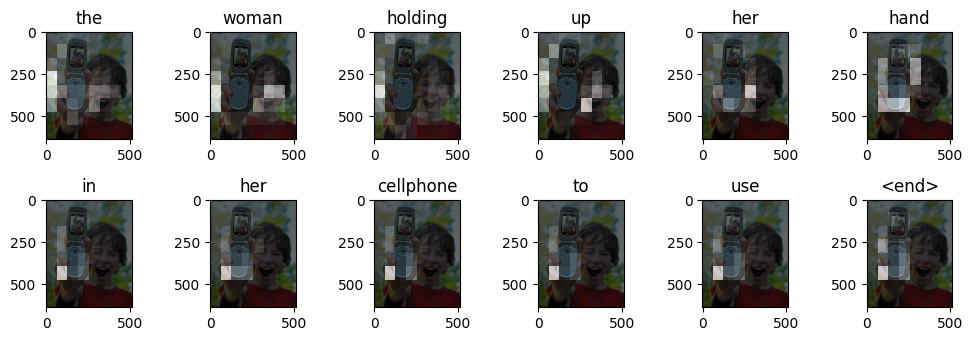

In [98]:
# Affichage de quelques annotations dans le jeu de test
rid = np.random.randint(0, len(img_name_val))
image = img_name_val[rid]
real_caption = ' '.join([tokenizer.index_word[i] for i in cap_val[rid] if i not in [0]])
result, attention_plot = evaluate(image)

print ('Real Caption:', real_caption)
print ('Prediction Caption:', ' '.join(result))
plot_attention(image, result, attention_plot)

ca c moi pour les images

In [99]:
import math
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

def plot_attention(image, result, attention_plot):
    temp_image = np.array(Image.open(image))

    ncols = 4
    nrows = math.ceil(len(result) / ncols)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(16, 4 * nrows),
        squeeze=False
    )

    for i, word in enumerate(result):
        ax = axes[i // ncols, i % ncols]

        # Image d'origine
        ax.imshow(temp_image)
        ax.set_title(word, fontsize=12)

        # Carte d'attention 8 × 8 superposée à l'image
        attention = np.array(attention_plot[i]).reshape(8, 8)
        ax.imshow(
            attention,
            cmap="jet",
            alpha=0.40,
            extent=(0, temp_image.shape[1], temp_image.shape[0], 0),
            interpolation="bilinear"
        )

        ax.axis("off")

    # Masquer les cases inutilisées de la dernière ligne
    for i in range(len(result), nrows * ncols):
        axes[i // ncols, i % ncols].axis("off")

    plt.tight_layout()
    plt.show()

Real Caption: the man is swinging at a tennis ball
Prediction Caption: a man playing a tennis match <end>


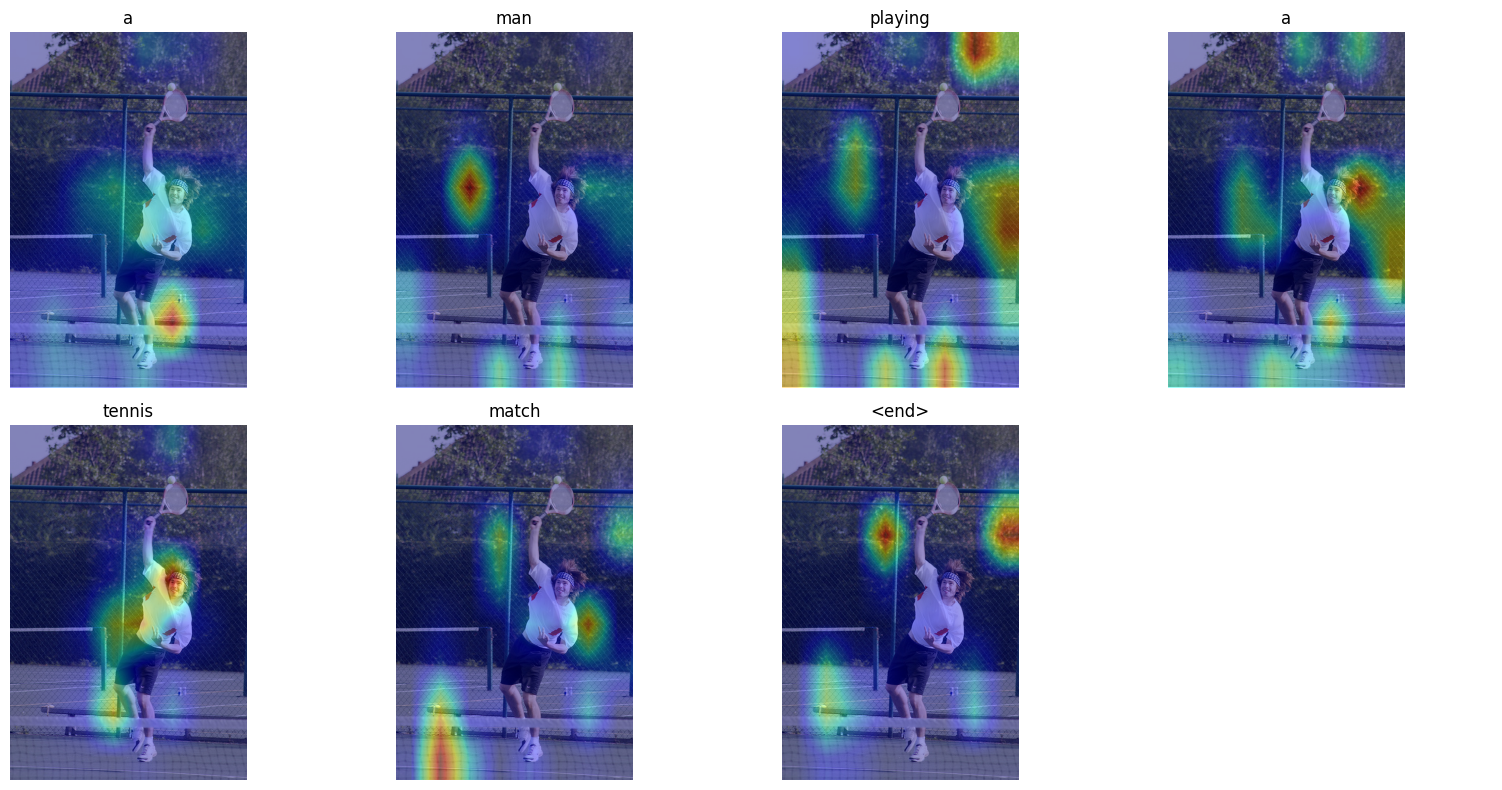

In [103]:
# Choisir une image de validation au hasard
rid = np.random.randint(0, len(img_name_val))
image = img_name_val[rid]

# evaluate renvoie seulement la prédiction et les poids d'attention
result, attention_plot = evaluate(image)

# Légende réelle associée à cette image
real_caption = [
    tokenizer.index_word.get(int(i), "<unk>")
    for i in cap_val[rid]
    if int(i) not in (
        0,
        tokenizer.word_index["<start>"],
        tokenizer.word_index["<end>"]
    )
]

print("Real Caption:", " ".join(real_caption))
print("Prediction Caption:", " ".join(result))

# Afficher l'image et les cartes d'attention
plot_attention(image, result, attention_plot)

## Courbes et accuracy de validation


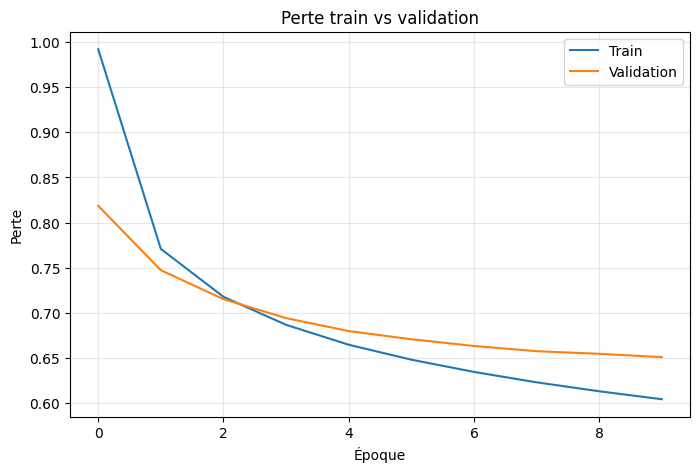

In [104]:
# Courbes de perte par époque (valeurs converties en float).
plt.figure(figsize=(8, 5))
plt.plot([float(x) for x in loss_plot], label="Train")
plt.plot([float(x) for x in validation_loss_plot], label="Validation")
plt.xlabel("Époque")
plt.ylabel("Perte")
plt.title("Perte train vs validation")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [ ]:
@tf.function
def validation_token_accuracy_step(img_tensor, target):
    """Accuracy token-level en teacher forcing, en ignorant le padding."""
    hidden = decoder.reset_state(batch_size=tf.shape(target)[0])
    dec_input = tf.fill([tf.shape(target)[0], 1], tokenizer.word_index["<start>"])
    features = encoder(img_tensor)
    correct = tf.constant(0, dtype=tf.float32)
    total = tf.constant(0, dtype=tf.float32)
    for i in range(1, target.shape[1]):
        predictions, hidden, _ = decoder(dec_input, features, hidden)
        predicted = tf.argmax(predictions, axis=-1, output_type=tf.int32)
        real = target[:, i]
        mask = tf.not_equal(real, 0)
        correct += tf.reduce_sum(tf.cast(tf.logical_and(tf.equal(predicted, real), mask), tf.float32))
        total += tf.reduce_sum(tf.cast(mask, tf.float32))
        dec_input = tf.expand_dims(real, 1)
    return correct, total

correct_tokens = tf.constant(0.0)
total_tokens = tf.constant(0.0)
for validation_img_tensor, validation_target in validation_dataset:
    batch_correct, batch_total = validation_token_accuracy_step(
        validation_img_tensor, validation_target
    )
    correct_tokens += batch_correct
    total_tokens += batch_total
validation_accuracy = 100.0 * correct_tokens / tf.maximum(total_tokens, 1.0)
print(f"Accuracy token-level validation (hors padding) : {float(validation_accuracy.numpy()):.2f} %")


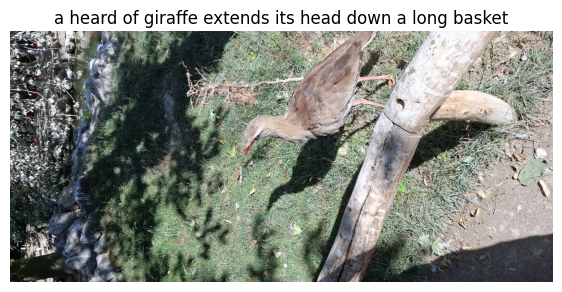

Légende générée : a heard of giraffe extends its head down a long basket


In [41]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

test_image = Path("test2.jpg")

if not test_image.exists():
    raise FileNotFoundError(f"Image introuvable : {test_image.resolve()}")

# Réencoder l'image en JPEG compatible avec load_image()
try:
    with Image.open(test_image) as source:
        image = source.convert("RGB")
        jpeg_path = test_image.with_name("test_reencoded.jpg").resolve()
        image.save(jpeg_path, format="JPEG", quality=95)
except Exception as e:
    raise ValueError(f"Impossible de lire l'image {test_image.resolve()} : {e}")

# evaluate() attend le chemin de l'image, pas un fichier .npy
result, attention_plot = evaluate(str(jpeg_path))

caption = " ".join(
    word for word in result
    if word not in ("<start>", "<end>", "<pad>")
)

plt.figure(figsize=(7, 7))
plt.imshow(image)
plt.axis("off")
plt.title(caption, fontsize=12)
plt.show()

print("Légende générée :", caption)